<a href="https://colab.research.google.com/github/inambaig24/TASKS/blob/main/Task2_Housing_Price_Prediction_Checked.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Real Estate Housing Price Prediction (Ridge & Lasso Regression)

**Goal:** Predict median house values using California Housing data and compare OLS, Ridge (L2), and Lasso (L1) regression with RMSE, MAE, and R².

The notebook covers missing-value imputation, correlation heatmap, interaction features, standardized preprocessing, GridSearchCV for Ridge and Lasso, predicted-vs-actual plots, and residual analysis.

## 1. Install required libraries (if needed)
In Google Colab, the libraries are usually already installed. If you see a `ModuleNotFoundError`, open a new code cell and run:

```python
!pip install pandas numpy matplotlib seaborn scikit-learn
```

Do not paste this command into a regular `.py` file; it is a notebook/Colab command.


## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 3. Load the California Housing dataset
The first run may need an active internet connection to download the dataset. If downloading fails, check your internet connection and rerun this cell. In Google Colab, use Runtime → Run all after the download works.


In [2]:
housing = fetch_california_housing(as_frame=True)
X = housing.data.copy()
y = housing.target.copy()

print("Dataset shape:", X.shape)
display(X.head())
print("\nMissing values before imputation:")
print(X.isnull().sum())

Dataset shape: (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



Missing values before imputation:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


## 4. Impute missing values and explore correlations
The original dataset usually has no missing values, but the imputer handles them if present.

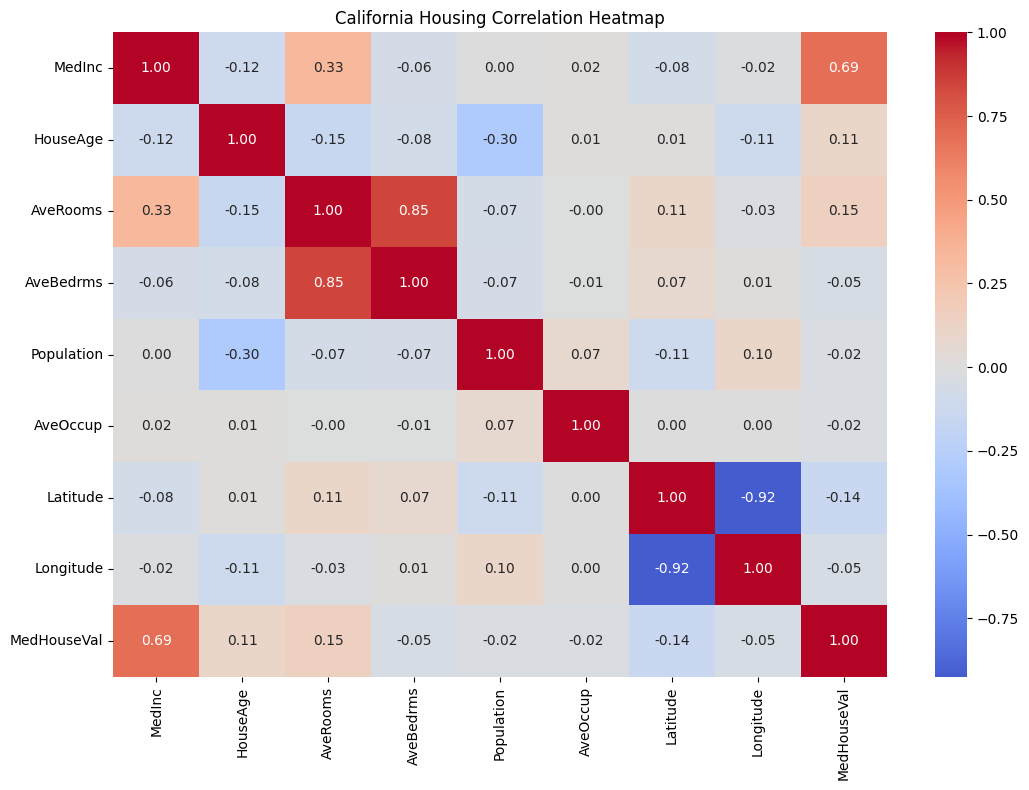

Missing values after imputation: 0


In [3]:
eda_imputer = SimpleImputer(strategy="median")
X_eda = pd.DataFrame(eda_imputer.fit_transform(X), columns=X.columns, index=X.index)
eda_df = X_eda.copy()
eda_df["MedHouseVal"] = y

plt.figure(figsize=(11, 8))
sns.heatmap(eda_df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("California Housing Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Missing values after imputation:", int(X_eda.isnull().sum().sum()))

## 5. Engineer interaction features
These selected interactions let the models represent combined effects of features.

In [4]:
X_features = X.copy()
X_features["MedInc_x_AveRooms"] = X_features["MedInc"] * X_features["AveRooms"]
X_features["HouseAge_x_AveOccup"] = X_features["HouseAge"] * X_features["AveOccup"]
X_features["Latitude_x_Longitude"] = X_features["Latitude"] * X_features["Longitude"]

print("Original feature count:", X.shape[1])
print("Feature count after interactions:", X_features.shape[1])
display(X_features.head())

Original feature count: 8
Feature count after interactions: 11


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedInc_x_AveRooms,HouseAge_x_AveOccup,Latitude_x_Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,58.144254,104.777778,-4630.0724
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,51.785271,44.306678,-4627.2492
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,60.150315,145.717514,-4626.7840
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,32.827897,132.493151,-4627.1625
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,24.161264,113.436293,-4627.1625


## 6. Split into training and testing data
The imputer and scaler used for modeling are fitted within each pipeline on training data only.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y, test_size=0.20, random_state=42
)

numeric_features = list(X_features.columns)
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features)
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


## 7. Train OLS, Ridge, and Lasso
GridSearchCV selects alpha for Ridge and Lasso using 5-fold cross-validation.

In [6]:
ols_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
ols_model.fit(X_train, y_train)

ridge_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)

lasso_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", Lasso(max_iter=20000))
])
lasso_search = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0]},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)
lasso_search.fit(X_train, y_train)

models = {
    "OLS (Linear Regression)": ols_model,
    "Ridge Regression": ridge_search.best_estimator_,
    "Lasso Regression": lasso_search.best_estimator_
}
print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])

Best Ridge alpha: 100.0
Best Lasso alpha: 0.01


## 8. Evaluate models using RMSE, MAE, and R²
Lower RMSE/MAE and higher R² are generally better.

In [7]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))

,Model,RMSE,MAE,R2
0,Lasso Regression,0.7404,0.5353,0.5816
1,Ridge Regression,0.7417,0.5329,0.5801
2,OLS (Linear Regression),0.7425,0.5329,0.5793


## 9. Plot predicted vs actual values

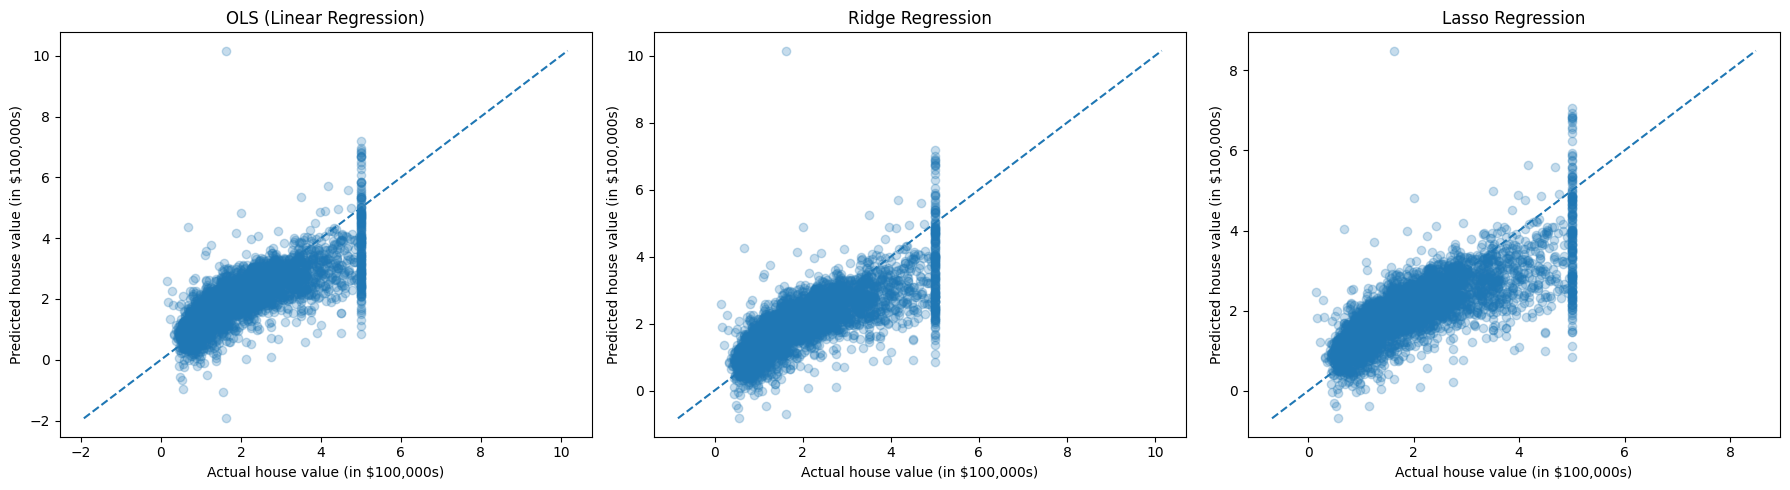

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.25)
    low = min(float(y_test.min()), float(np.min(y_pred)))
    high = max(float(y_test.max()), float(np.max(y_pred)))
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual house value (in $100,000s)")
    ax.set_ylabel("Predicted house value (in $100,000s)")
plt.tight_layout()
plt.show()

## 10. Residual analysis
Residual = actual value − predicted value. Residuals centered around zero without a strong pattern are generally desirable.

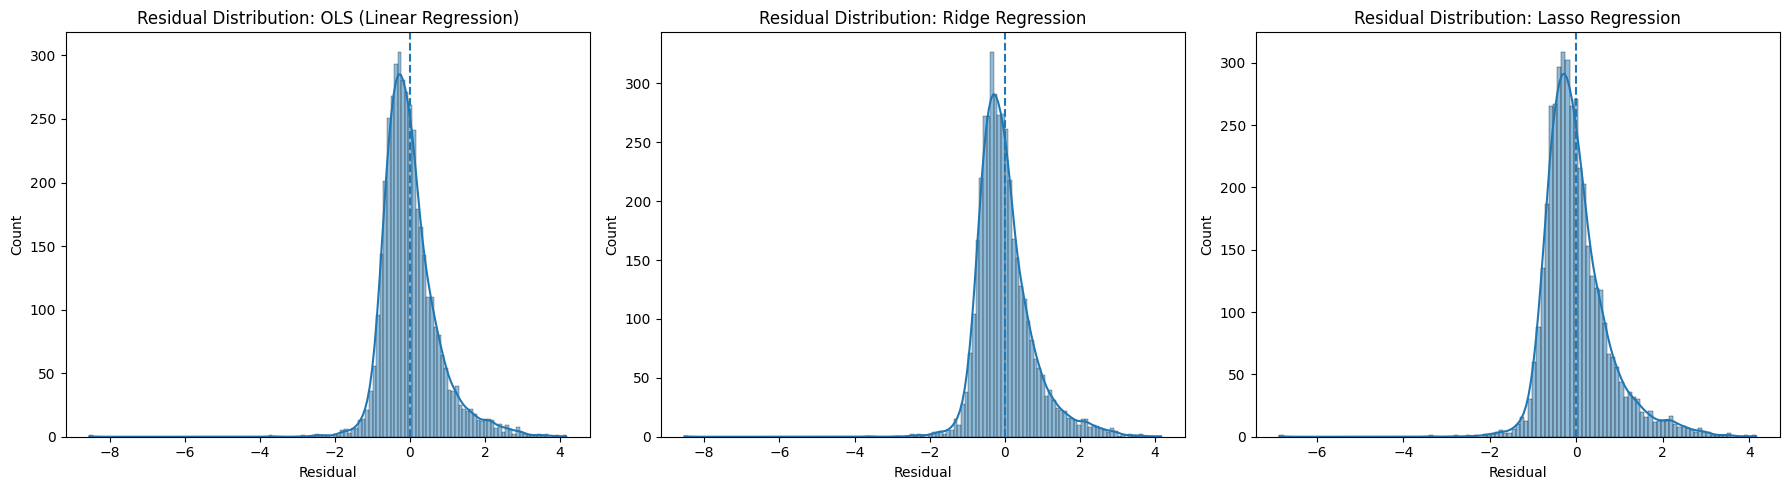

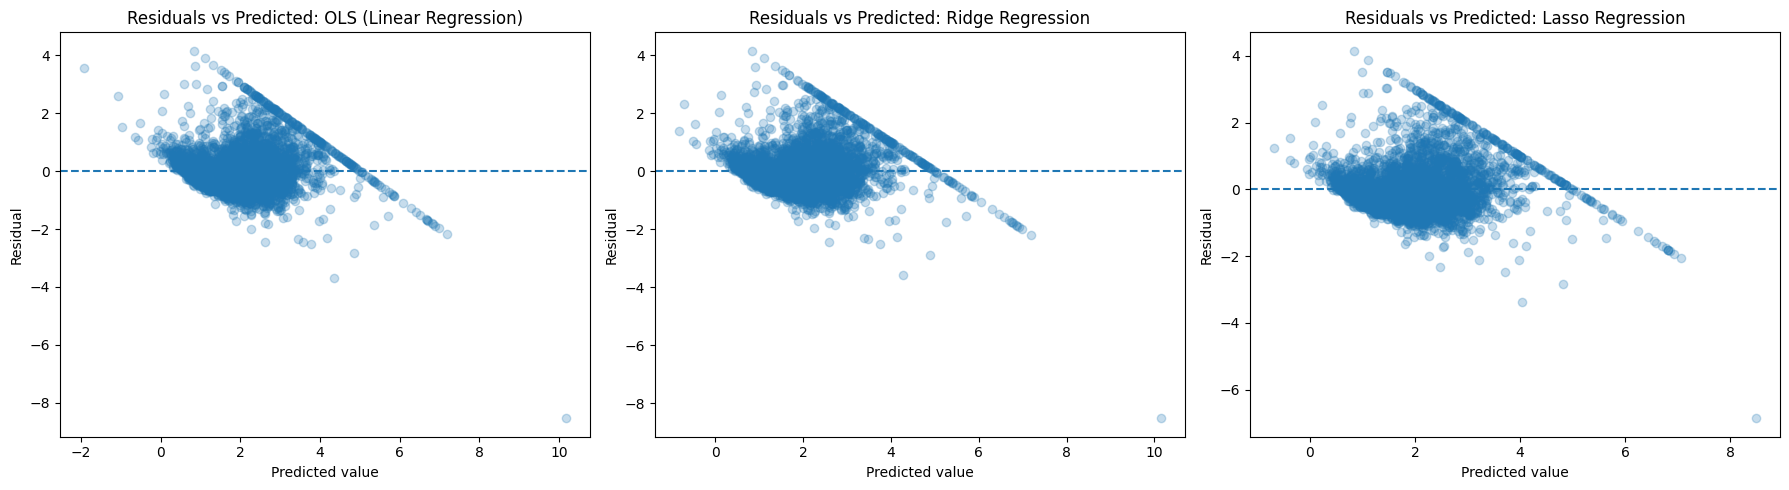

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred
    sns.histplot(residuals, kde=True, ax=ax)
    ax.axvline(0, linestyle="--")
    ax.set_title(f"Residual Distribution: {name}")
    ax.set_xlabel("Residual")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred
    ax.scatter(y_pred, residuals, alpha=0.25)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"Residuals vs Predicted: {name}")
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()

## 11. Conclusion from the measured results

In [10]:
best_rmse_model = results_df.loc[results_df["RMSE"].idxmin(), "Model"]
best_mae_model = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_r2_model = results_df.loc[results_df["R2"].idxmax(), "Model"]

print("Lowest RMSE:", best_rmse_model)
print("Lowest MAE:", best_mae_model)
print("Highest R²:", best_r2_model)
print("\nConclusion: Compare all three metrics together. The model with lower prediction errors and higher R² performs better on this test split.")

Lowest RMSE: Lasso Regression
Lowest MAE: OLS (Linear Regression)
Highest R²: Lasso Regression

Conclusion: Compare all three metrics together. The model with lower prediction errors and higher R² performs better on this test split.


## Submission checklist
1. Run all cells from top to bottom.
2. Make sure the metric table and plots appear.
3. Save/submit this `.ipynb` notebook through your internship platform.
4. The California Housing dataset may need an internet connection on the first run.